# 04 - Statistical Analysis & Hypothesis Testing
A **hypothesis test** checks whether a pattern seen in a sample is likely to be real or just random chance.
- **H0 (null):** no difference / no association.
- **H1 (alternative):** there is a difference / association.
- **p-value:** probability of seeing a result at least this extreme *if H0 were true*. If p < α (we use **α = 0.05**) we reject H0.
- A small p-value does **not** prove causation and does not say how *big* the effect is → we also report effect sizes.

In [1]:
# Import the libraries used in this notebook
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append("..")          # lets us import our own src/ package
from src import preprocessing as pp

np.random.seed(42)             # fixed seed for reproducibility
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)

In [2]:
df = pd.read_csv("../data/processed/cleaned_data.csv")
ALPHA = 0.05
fail = df[df[pp.TARGET_COL] == 1]
ok = df[df[pp.TARGET_COL] == 0]
print("Failure group:", len(fail), "| Non-failure group:", len(ok))

Failure group: 339 | Non-failure group: 9661


## Assumption check: are the groups normally distributed?

In [3]:
# Shapiro-Wilk on a random sample (max 500) - the test is over-sensitive for huge samples
rows = []
for col in pp.SENSOR_COLS:
    for name, g in [("Failure", fail), ("No failure", ok)]:
        s = g[col].sample(min(500, len(g)), random_state=42)
        rows.append({"variable": col, "group": name, "shapiro_p": stats.shapiro(s).pvalue,
                     "skew": round(g[col].skew(), 2)})
norm = pd.DataFrame(rows)
norm["looks_normal"] = norm["shapiro_p"] > ALPHA
norm

,variable,group,shapiro_p,skew,looks_normal
0,Air temperature [K],Failure,5.045478e-11,-0.54,False
1,Air temperature [K],No failure,1.996600e-07,0.13,False
2,Process temperature [K],Failure,4.058481e-05,-0.42,False
3,Process temperature [K],No failure,5.445124e-05,0.03,False
4,Rotational speed [rpm],Failure,1.227403e-28,2.53,False
5,Rotational speed [rpm],No failure,2.050304e-17,1.58,False
6,Torque [Nm],Failure,1.425004e-15,-1.20,False
7,Torque [Nm],No failure,7.882640e-01,-0.06,True
8,Tool wear [min],Failure,3.848150e-14,-0.51,False
9,Tool wear [min],No failure,7.481353e-11,0.03,False


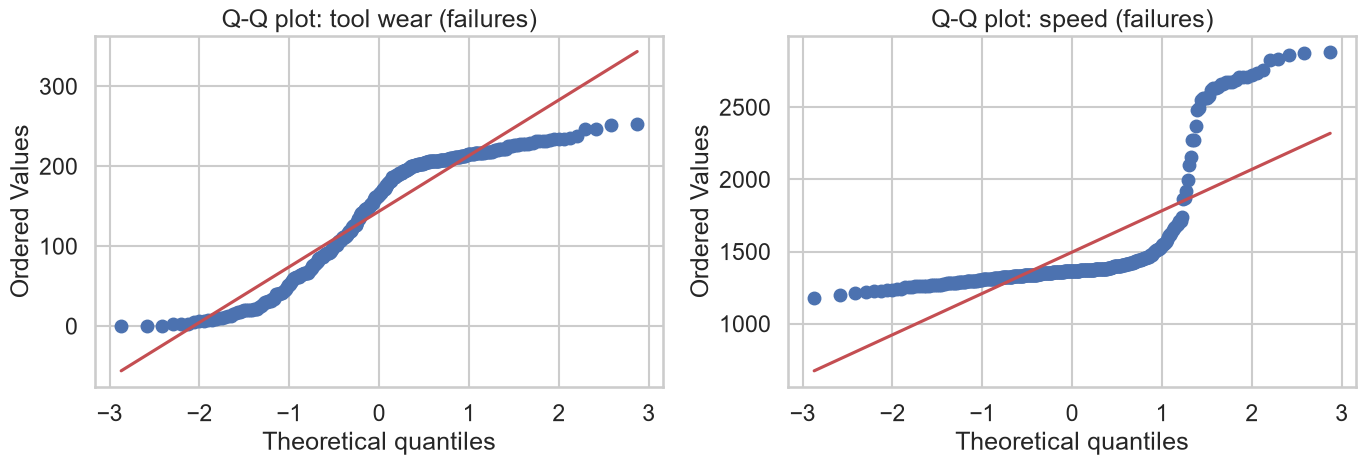

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
stats.probplot(fail["Tool wear [min]"], dist="norm", plot=axes[0]); axes[0].set_title("Q-Q plot: tool wear (failures)")
stats.probplot(fail["Rotational speed [rpm]"], dist="norm", plot=axes[1]); axes[1].set_title("Q-Q plot: speed (failures)")
plt.tight_layout(); plt.show()

Several variables are **not normal** and the groups have very different sizes and variances.
So our main test for numeric variables is the **Mann–Whitney U test** (non-parametric, compares distributions/medians, no normality needed).
**Welch's t-test** (does not assume equal variances) is reported alongside as a check on means.
Effect size: **rank-biserial correlation** r (−1 to 1; |r| ≈ 0.1 small, 0.3 medium, 0.5 large).

In [5]:
def compare_groups(col):
    a, b = fail[col], ok[col]
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    w = stats.ttest_ind(a, b, equal_var=False)
    r = 2 * u.statistic / (len(a) * len(b)) - 1        # rank-biserial: >0 means failure group higher
    return {"variable": col, "median_failure": a.median(), "median_no_failure": b.median(),
            "mean_failure": round(a.mean(), 2), "mean_no_failure": round(b.mean(), 2),
            "U": u.statistic, "mw_p": u.pvalue, "welch_t": round(w.statistic, 2), "welch_p": w.pvalue,
            "rank_biserial_r": round(r, 3)}

## Test 1 — Is tool wear different between failure and non-failure groups?
- **H0:** the distribution of tool wear is the same for failures and non-failures.
- **H1:** the distributions differ.
- **Variables:** tool wear (numeric, continuous) vs failure status (binary group).
- **Test:** Mann–Whitney U (non-normal, unequal group sizes), Welch's t-test as a check.

In [6]:
t1 = compare_groups("Tool wear [min]")
pd.Series(t1)

variable             Tool wear [min]
median_failure                 165.0
median_no_failure              107.0
mean_failure                  143.78
mean_no_failure               106.69
U                          2168468.0
mw_p                             0.0
welch_t                         9.26
welch_p                          0.0
rank_biserial_r                0.324
dtype: object

**Interpretation:** p is far below 0.05 → reject H0. Failed machines had a clearly higher median tool wear (165 vs 107 min) with a **medium** effect size.
**Practical meaning:** monitoring tool wear and replacing tools on time is likely valuable. This is an association; the data alone cannot prove that wear *causes* every failure.

## Test 2 — Do other sensor variables differ between failure groups?
- **H0 (for each variable):** same distribution in both groups. **H1:** distributions differ.
- Four tests at once → risk of false positives grows (**multiple-comparison problem**). We apply the **Holm correction** across all five numeric tests.

In [7]:
results = pd.DataFrame([compare_groups(c) for c in pp.SENSOR_COLS])

# Holm-Bonferroni correction (written by hand so no extra library is needed)
def holm(pvals):
    p = np.asarray(pvals); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj

results["mw_p_holm"] = holm(results["mw_p"])
results["significant_after_holm"] = results["mw_p_holm"] < ALPHA
results[["variable", "median_failure", "median_no_failure", "mw_p", "mw_p_holm",
         "rank_biserial_r", "welch_p", "significant_after_holm"]]

,variable,median_failure,median_no_failure,mw_p,mw_p_holm,rank_biserial_r,welch_p,significant_after_holm
0,Air temperature [K],301.6,300.0,8.656108e-17,1.731222e-16,0.265,1.950809e-14,True
1,Process temperature [K],310.4,310.0,6.486083e-05,6.486083e-05,0.127,1.151324e-04,True
2,Rotational speed [rpm],1365.0,1507.0,9.706908e-63,3.882763e-62,-0.533,3.764748e-02,True
3,Torque [Nm],53.7,39.9,2.262232e-64,1.131116e-63,0.540,3.635739e-27,True
4,Tool wear [min],165.0,107.0,2.916461e-24,8.749383e-24,0.324,1.906011e-18,True


**Interpretation (from the table):**
- All five variables differ significantly even after Holm correction.
- **Largest effects:** torque (higher in failures) and rotational speed (lower in failures), both |r| ≈ 0.5 (large).
- Air temperature: small-to-medium effect; process temperature: **small** effect — statistically significant but practically weak.
- For rotational speed, Welch's test (means) is much weaker than Mann–Whitney because failures include both very low and very high speeds — the means partly cancel. This shows why choosing the right test matters.

## Test 3 — Is product type associated with failure?
- **H0:** Type and failure status are independent. **H1:** they are associated.
- **Variables:** Type (categorical, 3 levels) × failure (binary).
- **Test:** Chi-square test of independence. **Assumption:** all expected counts ≥ 5.
- **Effect size:** Cramér's V (0 = none, 0.1 small, 0.3 medium).

In [8]:
table = pd.crosstab(df["Type"], df[pp.TARGET_COL]).reindex(["L", "M", "H"])
chi2, p, dof, expected = stats.chi2_contingency(table)
print("Observed:\n", table)
print("\nExpected:\n", pd.DataFrame(expected, index=table.index, columns=table.columns).round(1))
print("\nMin expected count:", expected.min().round(1), "-> assumption OK" if expected.min() >= 5 else "-> use Fisher's test")
n = table.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
print(f"chi2 = {chi2:.2f}, dof = {dof}, p = {p:.5f}, Cramér's V = {cramers_v:.3f}")
print("Failure rate by type:\n", (table[1] / table.sum(axis=1) * 100).round(2))

Observed:
 Machine failure     0    1
Type                      
L                5765  235
M                2914   83
H                 982   21

Expected:
 Machine failure       0      1
Type                          
L                5796.6  203.4
M                2895.4  101.6
H                 969.0   34.0

Min expected count: 34.0 -> assumption OK
chi2 = 13.75, dof = 2, p = 0.00103, Cramér's V = 0.037
Failure rate by type:
 Type
L    3.92
M    2.77
H    2.09
dtype: float64


**Interpretation:** p < 0.05 → reject H0: product type and failure are associated (L fails most, H least).
But Cramér's V is very small (~0.04) → the association is **real but weak**. Type alone is a poor predictor.

## Summary table

In [9]:
summary = results[["variable", "mw_p_holm", "rank_biserial_r"]].copy()
summary["test"] = "Mann-Whitney U (Holm)"
summary = pd.concat([summary, pd.DataFrame([{"variable": "Type", "mw_p_holm": p,
                                             "rank_biserial_r": round(cramers_v, 3),
                                             "test": "Chi-square (effect = Cramér's V)"}])])
summary.columns = ["variable", "p_value", "effect_size", "test"]
summary["reject_H0"] = summary["p_value"] < ALPHA
summary

,variable,p_value,effect_size,test,reject_H0
0,Air temperature [K],1.731222e-16,0.265,Mann-Whitney U (Holm),True
1,Process temperature [K],6.486083e-05,0.127,Mann-Whitney U (Holm),True
2,Rotational speed [rpm],3.882763e-62,-0.533,Mann-Whitney U (Holm),True
3,Torque [Nm],1.131116e-63,0.540,Mann-Whitney U (Holm),True
4,Tool wear [min],8.749383e-24,0.324,Mann-Whitney U (Holm),True
0,Type,1.032411e-03,0.037,Chi-square (effect = Cramér's V),True


## Conclusions
1. Failures are associated with higher tool wear, higher torque, lower (or extreme) speed and higher air temperature.
2. Product type has a statistically significant but weak association.
3. **Association ≠ causation**: the data is observational/synthetic; other factors could be involved.
4. With 10,000 rows even tiny differences become "significant", so effect sizes are essential.